# Trayectorias de ciclones tropicales en el Caribe

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/teoria-riesgos/blob/main/book/03_amenazas/315_trayectorias_ciclones.ipynb)

Este cuaderno **descarga datos reales** y produce la figura de trayectorias que usa el capítulo de [ciclones tropicales y vendavales](311_ciclones.md). Se puede ejecutar completo en Colab o en un computador, sin cuenta ni claves.

**Datos.** IBTrACS (*International Best Track Archive for Climate Stewardship*), versión 4, cuenca del Atlántico Norte, del NOAA/NCEI. Reúne las trayectorias oficiales («mejores trayectorias») de los centros de pronóstico; para el Atlántico proviene del Centro Nacional de Huracanes de Estados Unidos. Cita: Knapp et al. (2010), *Bulletin of the American Meteorological Society* 91(3), 363-376, [doi:10.1175/2009BAMS2755.1](https://doi.org/10.1175/2009BAMS2755.1); datos: Knapp et al. (2019), IBTrACS Project, Version 4, NOAA NCEI, [doi:10.25921/82ty-9e16](https://doi.org/10.25921/82ty-9e16) (archivo v04r01). Mapa base: Natural Earth (dominio público).

**Qué hace.**

1. Descarga y guarda en caché el archivo de la cuenca del Atlántico Norte (unos 58 MB) y los límites de países.
2. Se queda con los sistemas desde un año de inicio (por defecto 1980, la era satelital) y calcula la categoría Saffir-Simpson en cada punto con el viento sostenido.
3. Mide la distancia mínima de cada trayectoria a cuatro sitios de Colombia: San Andrés, Providencia, La Guajira (Cabo de la Vela) y Cartagena.
4. Dibuja la figura y cuenta cuántos sistemas pasaron cerca de cada sitio.

```{note}
Los parámetros están en la primera celda de código (año de inicio, distancia de referencia, sitios). Para otra región o periodo basta con cambiarlos.
```

In [1]:
from pathlib import Path
import io, zipfile, datetime
import numpy as np
import pandas as pd
import requests
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# ----------------------------- parámetros -----------------------------
ANIO_INICIO = 1980          # era satelital; las trayectorias anteriores son menos precisas
UMBRAL_KM = 250             # distancia de referencia a cada sitio
VIENTO_HURACAN = 64         # nudos (categoría 1 de Saffir-Simpson)
VIENTO_TORMENTA = 34        # nudos (tormenta tropical)
VENTANA = dict(lon=(-100, -50), lat=(5, 38))        # extensión de la figura general
CARIBE = dict(lon=(-90, -58), lat=(8, 25))          # un sistema "entra al Caribe" si pasa por esta caja
ZOOM = dict(lon=(-86, -68), lat=(8, 20))            # acercamiento al suroeste del Caribe

SITIOS = {                  # (lat, lon) aproximadas
    "San Andrés": (12.58, -81.70),
    "Providencia": (13.35, -81.37),
    "La Guajira (Cabo de la Vela)": (12.20, -72.18),
    "Cartagena": (10.39, -75.51),
}

URL_IBTRACS = ("https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs/"
               "v04r01/access/csv/ibtracs.NA.list.v04r01.csv")
URL_PAISES = "https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip"

DATOS, FIGURAS = Path("datos"), Path("figuras")
DATOS.mkdir(exist_ok=True); FIGURAS.mkdir(exist_ok=True)

# Escala Saffir-Simpson por viento sostenido (nudos): TD, TS, C1..C5
LIMITES = [0, 34, 64, 83, 96, 113, 137, 999]
ETIQUETAS = ["Depresión tropical", "Tormenta tropical", "Huracán cat. 1", "Huracán cat. 2",
             "Huracán cat. 3", "Huracán cat. 4", "Huracán cat. 5"]
COLORES = ["#9ecae1", "#41ab5d", "#fed976", "#fd8d3c", "#e31a1c", "#bd0026", "#6a0d83"]

## 1. Descarga (con caché)

In [2]:
def descargar(url, destino):
    """Descarga en bloques si el archivo no existe. Devuelve la ruta."""
    if destino.exists():
        print(f"En caché: {destino} ({destino.stat().st_size/1e6:.0f} MB)")
        return destino
    print(f"Descargando {url} ...")
    with requests.get(url, stream=True, timeout=120, headers={"User-Agent": "teoria-riesgos-cuaderno"}) as r:
        r.raise_for_status()
        with open(destino, "wb") as f:
            for bloque in r.iter_content(1 << 20):
                f.write(bloque)
    print(f"  listo: {destino.stat().st_size/1e6:.0f} MB")
    return destino

ruta_csv = descargar(URL_IBTRACS, DATOS / "ibtracs.NA.list.v04r01.csv")
ruta_zip = descargar(URL_PAISES, DATOS / "ne_50m_admin_0_countries.zip")

cab = requests.head(URL_IBTRACS, timeout=60, headers={"User-Agent": "teoria-riesgos-cuaderno"}).headers
print("Última modificación del archivo en el servidor:", cab.get("Last-Modified"))
print("Fecha de esta ejecución:", datetime.date.today().isoformat())

En caché: datos/ibtracs.NA.list.v04r01.csv (58 MB)
En caché: datos/ne_50m_admin_0_countries.zip (1 MB)


Última modificación del archivo en el servidor: Sun, 01 Nov 2026 10:03:22 GMT
Fecha de esta ejecución: 2026-11-02


## 2. Lectura y limpieza

El archivo tiene dos filas de encabezado (nombres y unidades) y muchas columnas; se leen solo las necesarias. Se conservan las trayectorias principales (`TRACK_TYPE == "main"`) y se usa el viento sostenido en nudos (`USA_WIND`, del Centro Nacional de Huracanes; si falta, el viento oficial `WMO_WIND`).

In [3]:
cols = ["SID", "SEASON", "NAME", "ISO_TIME", "NATURE", "LAT", "LON", "TRACK_TYPE", "USA_WIND", "WMO_WIND"]
df = pd.read_csv(ruta_csv, usecols=cols, skiprows=[1], low_memory=False)
for c in ["SEASON", "LAT", "LON", "USA_WIND", "WMO_WIND"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["ISO_TIME"] = pd.to_datetime(df["ISO_TIME"], errors="coerce")
df["viento"] = df["USA_WIND"].fillna(df["WMO_WIND"])

df = df[(df.TRACK_TYPE == "main") & (df.SEASON >= ANIO_INICIO) & df.LAT.notna() & df.LON.notna()].copy()
df = df.sort_values(["SID", "ISO_TIME"]).reset_index(drop=True)
df["categoria"] = pd.cut(df["viento"], LIMITES, labels=False, right=False)   # 0=TD ... 6=C5; NaN si no hay viento
print(f"{df.SID.nunique()} sistemas del Atlántico Norte desde {ANIO_INICIO}; {len(df):,} posiciones")
print("Periodo cubierto:", df.ISO_TIME.min().date(), "a", df.ISO_TIME.max().date())
df.head(3)

743 sistemas del Atlántico Norte desde 1980; 41,500 posiciones
Periodo cubierto: 1980-07-17 a 2025-11-01


,SID,SEASON,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,TRACK_TYPE,USA_WIND,viento,categoria
0,1980199N31284,1980,UNNAMED,1980-07-17 00:00:00,TS,30.5,-76.5,20.0,main,20.0,20.0,0.0
1,1980199N31284,1980,UNNAMED,1980-07-17 03:00:00,TS,30.3,-76.9,NaN,main,23.0,23.0,0.0
2,1980199N31284,1980,UNNAMED,1980-07-17 06:00:00,TS,30.2,-77.2,25.0,main,25.0,25.0,0.0


In [4]:
# Resumen por sistema
sis = (df.groupby("SID")
         .agg(nombre=("NAME", "first"), anio=("SEASON", "first"), vmax=("viento", "max"),
              inicio=("ISO_TIME", "min"))
         .reset_index())
sis["nombre"] = sis.nombre.str.title()
print(f"Con viento máximo ≥ {VIENTO_TORMENTA} kt (tormenta tropical o más): {(sis.vmax >= VIENTO_TORMENTA).sum()}")
print(f"Con viento máximo ≥ {VIENTO_HURACAN} kt (huracán): {(sis.vmax >= VIENTO_HURACAN).sum()}")

def haversine(lat1, lon1, lat2, lon2):
    """Distancia en km sobre la esfera (arrays o escalares)."""
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

for nombre, (la, lo) in SITIOS.items():
    df["d_" + nombre] = haversine(df.LAT, df.LON, la, lo)

Con viento máximo ≥ 34 kt (tormenta tropical o más): 631
Con viento máximo ≥ 64 kt (huracán): 321


## 3. ¿Qué sistemas pasan cerca de Colombia?

Para cada sitio se toma, de cada sistema, el punto de la trayectoria más cercano. La tabla cuenta los sistemas que pasaron a menos de la distancia de referencia, separados por intensidad (viento máximo del sistema **dentro** de esa distancia).

In [5]:
def cerca(sitio, km=UMBRAL_KM):
    """Una fila por sistema que pasó a menos de `km` del sitio: distancia mínima y viento máximo dentro del radio."""
    d = df["d_" + sitio]
    dentro = df[d <= km]
    r = (dentro.groupby("SID")
               .agg(dmin=("d_" + sitio, "min"), vmax_cerca=("viento", "max"),
                    nombre=("NAME", "first"), anio=("SEASON", "first")).reset_index())
    r["nombre"] = r.nombre.str.title()
    return r

CERCA = {s: cerca(s) for s in SITIOS}
filas = []
for s, r in CERCA.items():
    filas.append({"sitio": s,
                  f"sistemas a < {UMBRAL_KM} km": len(r),
                  "con viento ≥ 34 kt dentro del radio": int((r.vmax_cerca >= VIENTO_TORMENTA).sum()),
                  "con viento ≥ 64 kt dentro del radio": int((r.vmax_cerca >= VIENTO_HURACAN).sum())})
resumen = pd.DataFrame(filas).set_index("sitio")
print(f"Periodo {ANIO_INICIO}-{df.SEASON.max():.0f}  ({df.SEASON.max() - ANIO_INICIO + 1:.0f} temporadas)")
resumen

Periodo 1980-2025  (46 temporadas)


,sistemas a < 250 km,con viento ≥ 34 kt dentro del radio,con viento ≥ 64 kt dentro del radio
sitio,,,
San Andrés,35,18,9
Providencia,40,19,9
La Guajira (Cabo de la Vela),16,10,3
Cartagena,8,4,1


In [6]:
# Sistemas con viento de huracán dentro del radio de San Andrés o Providencia
arch = pd.concat([CERCA["San Andrés"].assign(sitio="San Andrés"), CERCA["Providencia"].assign(sitio="Providencia")])
arch = (arch[arch.vmax_cerca >= VIENTO_HURACAN].sort_values("dmin")
            .drop_duplicates("SID")[["nombre", "anio", "dmin", "vmax_cerca"]])
arch.columns = ["nombre", "año", "distancia mínima (km)", "viento máx. dentro del radio (kt)"]
arch.round(0).reset_index(drop=True)

,nombre,año,distancia mínima (km),viento máx. dentro del radio (kt)
0,Beta,2005,18.0,100.0
1,Iota,2020,22.0,135.0
2,Julia,2022,34.0,75.0
3,Otto,2016,53.0,100.0
4,Cesar,1996,76.0,75.0
5,Joan:Miriam,1988,87.0,125.0
6,Ida,2009,102.0,70.0
7,Felix,2007,118.0,140.0
8,Eta,2020,161.0,130.0


## 4. La figura

Dos paneles. A la izquierda, los **huracanes** (viento máximo ≥ 64 kt) que entraron al Caribe, con cada tramo coloreado por la categoría que tenía el sistema en ese punto. A la derecha, un acercamiento al suroeste del Caribe con los **sistemas que pasaron a menos de la distancia de referencia** de los cuatro sitios de Colombia (tormentas tropicales y huracanes).

Huracanes que entraron al Caribe: 192; sistemas cerca de Colombia: 25


Figura guardada en figuras/trayectorias_ciclones_caribe.png


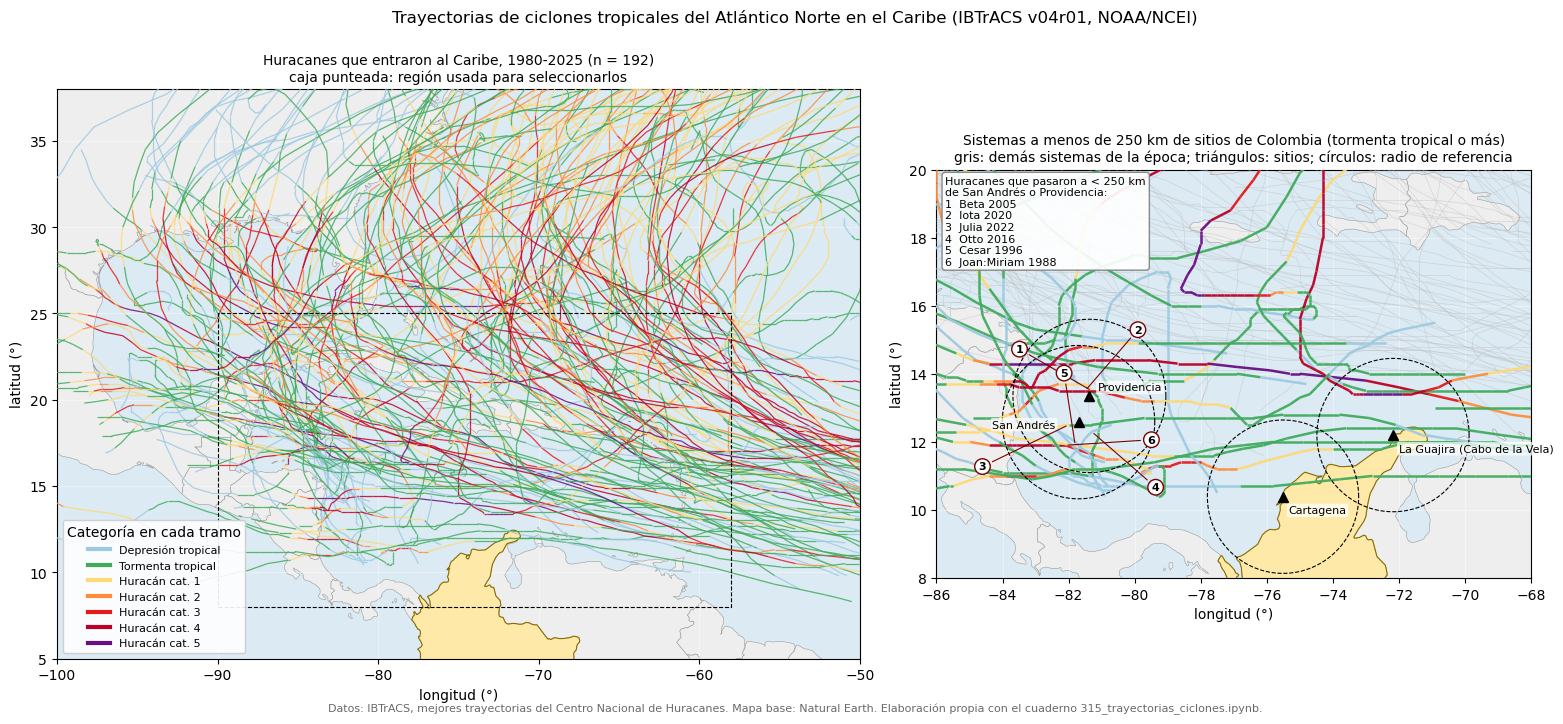

In [7]:
paises = gpd.read_file(f"zip://{ruta_zip}")
colombia = paises[paises.NAME == "Colombia"]

def dibujar_base(ax, ext):
    paises.plot(ax=ax, color="#eeeeee", edgecolor="#9a9a9a", linewidth=0.4, zorder=1)
    colombia.plot(ax=ax, color="#ffe9a8", edgecolor="#8a6d00", linewidth=0.8, zorder=2)
    ax.set_xlim(*ext["lon"]); ax.set_ylim(*ext["lat"])
    ax.set_aspect(1 / np.cos(np.radians(np.mean(ext["lat"]))))
    ax.set_facecolor("#dbeaf3")
    ax.grid(color="white", alpha=0.6, lw=0.5)
    ax.set_xlabel("longitud (°)"); ax.set_ylabel("latitud (°)")

def segmentos(g):
    xy = g[["LON", "LAT"]].to_numpy()
    seg = np.stack([xy[:-1], xy[1:]], axis=1)
    cat = g["categoria"].to_numpy()[:-1]
    return seg, cat

def dibujar_trayectorias(ax, sids, lw=1.0, alpha=0.9, solo_gris=False):
    segs, cols = [], []
    for sid, g in df[df.SID.isin(sids)].groupby("SID"):
        if len(g) < 2:
            continue
        s, c = segmentos(g)
        segs.append(s)
        cols.append(np.where(np.isnan(c), 0, c).astype(int))
    if not segs:
        return
    segs, cols = np.concatenate(segs), np.concatenate(cols)
    color = ["#bdbdbd"] * len(cols) if solo_gris else [COLORES[i] for i in cols]
    ax.add_collection(LineCollection(segs, colors=color, linewidths=lw, alpha=alpha, zorder=3))

def circulo(lat, lon, km, n=120):
    """Círculo geodésico aproximado (en lon, lat) de radio `km`."""
    ang = np.linspace(0, 2 * np.pi, n)
    dlat = (km / 111.0) * np.sin(ang)
    dlon = (km / (111.0 * np.cos(np.radians(lat)))) * np.cos(ang)
    return lon + dlon, lat + dlat

# --- selección de sistemas
en_caribe = df[(df.LON.between(*CARIBE["lon"])) & (df.LAT.between(*CARIBE["lat"]))].SID.unique()
huracanes_caribe = sis[(sis.SID.isin(en_caribe)) & (sis.vmax >= VIENTO_HURACAN)].SID
sids_cerca = set()
for s, r in CERCA.items():
    sids_cerca |= set(r[r.vmax_cerca >= VIENTO_TORMENTA].SID)
print(f"Huracanes que entraron al Caribe: {len(huracanes_caribe)}; sistemas cerca de Colombia: {len(sids_cerca)}")

fig, ax = plt.subplots(1, 2, figsize=(16, 7.2), gridspec_kw=dict(width_ratios=[1.35, 1]))

# Panel izquierdo
dibujar_base(ax[0], VENTANA)
dibujar_trayectorias(ax[0], set(huracanes_caribe), lw=0.9, alpha=0.85)
ax[0].add_patch(plt.Rectangle((CARIBE["lon"][0], CARIBE["lat"][0]), CARIBE["lon"][1] - CARIBE["lon"][0],
                              CARIBE["lat"][1] - CARIBE["lat"][0], fill=False, ls="--", ec="k", lw=0.8, zorder=4))
ax[0].set_title(f"Huracanes que entraron al Caribe, {ANIO_INICIO}-{df.SEASON.max():.0f} (n = {len(huracanes_caribe)})\n"
                "caja punteada: región usada para seleccionarlos", fontsize=10)

# Panel derecho
dibujar_base(ax[1], ZOOM)
otros = set(sis[(sis.vmax >= VIENTO_TORMENTA)].SID) - sids_cerca
dibujar_trayectorias(ax[1], otros, lw=0.5, alpha=0.5, solo_gris=True)
dibujar_trayectorias(ax[1], sids_cerca, lw=1.8, alpha=0.95)
for nombre, (la, lo) in SITIOS.items():
    cx, cy = circulo(la, lo, UMBRAL_KM)
    ax[1].plot(cx, cy, "k--", lw=0.8, zorder=5)
    ax[1].plot(lo, la, "k^", ms=7, zorder=6)
    despl = (-62, -4) if nombre == "San Andrés" else ((4, -12) if nombre != "Providencia" else (6, 4))
    ax[1].annotate(nombre, (lo, la), xytext=despl, textcoords="offset points", fontsize=8, zorder=7,
                   bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
# numerar los huracanes que pasaron por el archipiélago (la lista va en un recuadro, para que no se encimen)
DESPLAZ = [(-52, 30), (38, 44), (-62, -30), (46, -40), (-8, 52), (62, 4)]    # desplazamiento de cada número (puntos)
lista = []
for k, (_, f) in enumerate(arch.head(6).iterrows()):
    sid = sis[(sis.nombre == f["nombre"]) & (sis.anio == f["año"])].SID.iloc[0]
    g = df[df.SID == sid]
    d = np.minimum(g["d_San Andrés"], g["d_Providencia"])
    p = g.loc[d.idxmin()]
    ax[1].annotate(str(k + 1), (p.LON, p.LAT), xytext=DESPLAZ[k], textcoords="offset points", fontsize=8,
                   fontweight="bold", ha="center", va="center", zorder=9,
                   bbox=dict(boxstyle="circle,pad=0.25", fc="white", ec="#7a0000", lw=1),
                   arrowprops=dict(arrowstyle="-", color="#7a0000", lw=0.8))
    lista.append(f"{k + 1}  {f['nombre']} {int(f['año'])}")
ax[1].text(0.015, 0.985, "Huracanes que pasaron a < %d km\nde San Andrés o Providencia:\n" % UMBRAL_KM + "\n".join(lista),
           transform=ax[1].transAxes, fontsize=8, va="top", zorder=10,
           bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.92))
ax[1].set_title(f"Sistemas a menos de {UMBRAL_KM} km de sitios de Colombia (tormenta tropical o más)\n"
                "gris: demás sistemas de la época; triángulos: sitios; círculos: radio de referencia", fontsize=10)

leyenda = [Line2D([0], [0], color=c, lw=3, label=e) for c, e in zip(COLORES, ETIQUETAS)]
ax[0].legend(handles=leyenda, loc="lower left", fontsize=8, title="Categoría en cada tramo", framealpha=0.9)
fig.suptitle("Trayectorias de ciclones tropicales del Atlántico Norte en el Caribe (IBTrACS v04r01, NOAA/NCEI)", fontsize=12)
fig.text(0.5, 0.005, "Datos: IBTrACS, mejores trayectorias del Centro Nacional de Huracanes. Mapa base: Natural Earth. "
         "Elaboración propia con el cuaderno 315_trayectorias_ciclones.ipynb.", ha="center", fontsize=8, color="dimgray")
plt.tight_layout(rect=(0, 0.02, 1, 0.97))
SALIDA = FIGURAS / "trayectorias_ciclones_caribe.png"
fig.savefig(SALIDA, dpi=125, bbox_inches="tight")
print("Figura guardada en", SALIDA)
plt.show()

## 5. Qué hay que tener presente al leer la figura

- **Son mejores trayectorias, no mediciones.** El Centro Nacional de Huracanes las reconstruye después de cada temporada. La intensidad entre observaciones se interpola; el viento sostenido tiene incertidumbre.
- **El periodo es corto frente a la frecuencia de eventos raros.** Unas cuatro décadas dan una idea del patrón, pero pocos sistemas pasan cerca de un punto dado; un conteo de uno o dos sistemas no permite estimar un periodo de retorno. Para la amenaza se usa un conjunto estocástico de ciclones, como el del Atlas de Riesgo de Colombia.
- **La distancia no es el impacto.** Que un ciclón pase a 250 km no dice cuánto viento, lluvia o marea de tormenta recibe un sitio; eso depende del tamaño del sistema y de su lado (derecho o izquierdo) respecto del punto. El daño también depende de la exposición y la vulnerabilidad.
- **Las coordenadas de los sitios son aproximadas** y se pueden cambiar en la primera celda de código.

## 6. Reproducir o adaptar

| Quiero… | Cambio |
|---|---|
| Otro periodo | `ANIO_INICIO` (la base llega hasta 1851, con menos precisión antes de la era satelital) |
| Otra ciudad o región | `SITIOS`, `ZOOM` y `VENTANA` |
| Otra distancia de referencia | `UMBRAL_KM` |
| Otra cuenca (Pacífico oriental, por ejemplo) | Cambiar `URL_IBTRACS` por el archivo `ibtracs.EP.list.v04r01.csv` |